<a href="https://colab.research.google.com/github/bosic2/AlgoCom/blob/main/Benchmarking_UpgradeSystem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Benchmarking Algorithms: Upgrade System

**[Problem]:**

Building a simple upgrade system that allows for upgrade paths.

**[Algorithms Used]:**

1. DFS-Based Topological Sort

2. Kahn's Algorithm

3. Standard GraphLib

**[Metrics]**
1. Speed
2. Scalability
3. Functionality

 Graph_Nodes  DFS_Sort Kahns_Algorithm   Graphlib
          10 0.0060 ms       0.0037 ms  0.0158 ms
          50 0.0149 ms       0.0262 ms  0.1047 ms
         100 0.0362 ms       0.0434 ms  0.2491 ms
         250 0.1482 ms       0.1778 ms  1.0007 ms
         500 0.3453 ms       0.7662 ms  5.9647 ms
         750 0.6500 ms       1.6086 ms  8.1210 ms
        1000 1.0687 ms       3.0796 ms 14.1522 ms


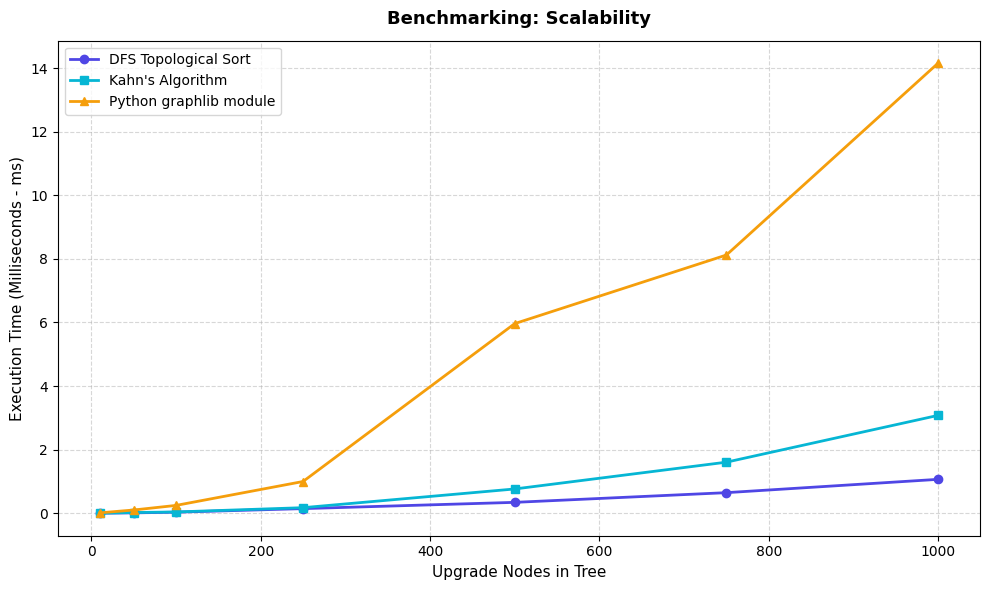

In [ ]:
import time
import collections
import graphlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

class TechTreeGraph:
    def __init__(self, num_nodes=100, edge_probability=0.04):
        self.num_nodes = num_nodes
        self.adj = collections.defaultdict(list)
        self.in_degree = {i: 0 for i in range(num_nodes)}

        for u in range(num_nodes):
            for v in range(u + 1, num_nodes):
                if np.random.rand() < edge_probability:
                    self.adj[u].append(v)
                    self.in_degree[v] += 1

    # Algorithm 1: DFS-based topological sort
    def topo_sort_dfs(self):
        visited = set()
        stack = []

        def dfs_visit(node):
            visited.add(node)
            for neighbor in self.adj[node]:
                if neighbor not in visited:
                    dfs_visit(neighbor)
            stack.append(node)

        for i in range(self.num_nodes):
            if i not in visited:
                dfs_visit(i)

        return stack[::-1]

    # Algorithm 2: Kahn's Algorithm
    def topo_sort_kahns(self):
        in_deg = self.in_degree.copy()
        queue = collections.deque([u for u in in_deg if in_deg[u] == 0])
        order = []

        while queue:
            u = queue.popleft()
            order.append(u)
            for v in self.adj[u]:
                in_deg[v] -= 1
                if in_deg[v] == 0:
                    queue.append(v)
        return order

    # Algorithm 3: Standard GraphLib
    def topo_sort_graphlib(self):
        ts = graphlib.TopologicalSorter()
        for u in range(self.num_nodes):
            for v in self.adj[u]:
                ts.add(v, u)
            if u not in self.adj and self.in_degree[u] == 0:
                ts.add(u)

        try:
            return list(ts.static_order())
        except graphlib.CycleError:
            return []

if __name__ == "__main__":
    node_sizes = [10, 50, 100, 250, 500, 750, 1000]
    results = []
    iterations = 50

    for size in node_sizes:
        graph = TechTreeGraph(num_nodes=size, edge_probability=0.03)

        # 1. Benchmark DFS
        t0 = time.perf_counter()
        for _ in range(iterations):
            graph.topo_sort_dfs()
        t_dfs = ((time.perf_counter() - t0) / iterations) * 1000  # Milliseconds

        # 2. Benchmark Kahn's
        t0 = time.perf_counter()
        for _ in range(iterations):
            graph.topo_sort_kahns()
        t_kahn = ((time.perf_counter() - t0) / iterations) * 1000

        # 3. Benchmark Graphlib
        t0 = time.perf_counter()
        for _ in range(iterations):
            graph.topo_sort_graphlib()
        t_gl = ((time.perf_counter() - t0) / iterations) * 1000

        results.append({
            "Graph_Nodes": size,
            "DFS_Sort": t_dfs,
            "Kahns_Algorithm": t_kahn,
            "Graphlib": t_gl
        })


    df = pd.DataFrame(results)
    print(df.to_string(index=False, formatters={
        "DFS_Sort": "{:.4f} ms".format,
        "Kahns_Algorithm": "{:.4f} ms".format,
        "Graphlib": "{:.4f} ms".format
    }))

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(df['Graph_Nodes'], df['DFS_Sort'], label='DFS Topological Sort', color='#4f46e5', marker='o', linewidth=2)
    ax.plot(df['Graph_Nodes'], df['Kahns_Algorithm'], label="Kahn's Algorithm", color='#06b6d4', marker='s', linewidth=2)
    ax.plot(df['Graph_Nodes'], df['Graphlib'], label='Python graphlib module', color='#f59e0b', marker='^', linewidth=2)

    ax.set_xlabel('Upgrade Nodes in Tree', fontsize=11)
    ax.set_ylabel('Execution Time (Milliseconds - ms)', fontsize=11)
    ax.set_title('Benchmarking: Scalability', fontsize=13, fontweight='bold', pad=12)
    ax.legend(loc='upper left')
    ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

## Results

### 1. Speed
As we can see, the **DFS-based topological sort** is the fastest algorithm, running at 1.1 milliseconds at 1000 nodes. **Kahn's Algorithm** is the 2nd fastest, almost equal with it on lower upgrade node counts. The execution time in 3.08 milliseconds at 1000 nodes. The **Graphlib** algorithm serves as a baseline to compare against the two algorithms.

### 2. Scalability
Graphlib at higher node counts past 200 becomes much slower than the other two algorithm. Kahn's Algroithm becomes slightly slower than DFS-based Topological Sort, but only past 200. At less than 200 nodes, they are roughly the same speed.

### 3. Functionality
Graphlib is more dynamic while Kahn's Algorithm and DFS-based Topological Sort are more static. DFS-based Topological Sort is more prone to errors via recursion, and Kahn's Algorithm has measures against cyclical errors by detecting if processed nodes ≠ total vertices.

## Conclusion

In the end, we chose Kahn's Algorithm, as it's more customizable and allows for easier checking for cyclical errors where a node requires unlocking itself before it becomes accessible, thus making development more error-free and convenient. It is also quite fast, running on par with DFS-based Topological sort at a low node count.